# Can tumour gene expression predict prostate-cancer recurrence? An honest evaluation

**Group project · gene expression · my implementation**, Seid Adem

> **Why this matters, in plain language.** After prostate-cancer surgery, about one patient in three sees the cancer
> come back within a few years ("recurrence"). Doctors already estimate that risk from the tumour's **ISUP grade**
> (how abnormal the cells look under the microscope), its **stage** (how far it has spread locally) and the blood
> marker **PSA**. The project asks whether the activity of 20,530 genes in the tumour (its **gene expression**,
> measured by RNA sequencing) can predict recurrence.
>
> With 243 patients and 20,530 genes, this is a textbook **p ≫ n** problem: far more measurements than patients.
> It is very easy to find genes that "predict" recurrence by chance, and very easy to fool yourself while
> evaluating. ([Lessons 1–3](../LESSONS.md))

The course notebooks compare gene-selection strategies and classifiers on one 70/30 split. I ask three questions they
don't:

1. **What do the clinical variables alone achieve?** Any expression model has to beat this to be useful.
2. **How much do the scores depend on *where* genes are selected** (before vs inside cross-validation)?
3. **How much of the difference between models is just the luck of one split?**

*Data: TCGA prostate adenocarcinoma (PRAD), as prepared by the course: 243 patients with log-scale RNA-seq expression
and the outcome `recurrence.3y` (progression within 3 years; patients followed for less than 3 years without an event
were excluded by the course).*

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadr
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from dsls.expression import GeneSelector

warnings.filterwarnings("ignore", category=FutureWarning)
# Parallel worker processes print two harmless messages (a NumPy reduce warning and a loky worker-restart notice);
# the same fits run warning-free in a single process. Silence just those two in the workers.
os.environ["PYTHONWARNINGS"] = (
    "ignore:invalid value encountered in reduce:RuntimeWarning,ignore:A worker stopped:UserWarning"
)
warnings.filterwarnings("ignore", message="A worker stopped", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
DATA = Path("../../../data/raw/gene_expression")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
SEED = 0

## 1 · The data and the clinical picture

In [2]:
expr = pyreadr.read_r(DATA / "gene_expresion_prostate_cancer.RDS")[None]
pheno = pyreadr.read_r(DATA / "pheno_prostate_cancer.RDS")[None]
assert (expr.index == pheno.index).all()
expr = expr.loc[:, expr.sum() > 0]  # drop genes never detected
y = pheno["recurrence.3y"].astype(int).to_numpy()
literature = open(DATA / "genes_cancer_prostata_bibliografia.txt").read().split()

clinical = pd.DataFrame({
    "ISUP grade": pheno["ISUP_group"].astype(int),
    "T stage": pheno["pathologic_T_simple"].astype(str).str[1].replace("a", np.nan).astype(float),
    "log PSA": np.log2(pheno["PSA"].astype(float).fillna(1)).where(pheno["PSA"].notna()),
    "age": pheno["age"].astype(float),
}, index=pheno.index)  # fmt: skip
print(f"{expr.shape[0]} patients × {expr.shape[1]:,} detected genes; {y.sum()} recurrences ({y.mean():.0%}); "
      f"literature list: {len(literature)} genes, {sum(g in expr.columns for g in literature)} present")  # fmt: skip
print("missing values:", clinical.isna().sum().to_dict())

table = pd.crosstab(clinical["ISUP grade"], np.where(y == 1, "recurrence", "no recurrence"))
table["recurrence rate"] = (table["recurrence"] / table.sum(axis=1)).round(2)
display(table)

243 patients × 20,174 detected genes; 72 recurrences (30%); literature list: 490 genes, 490 present
missing values: {'ISUP grade': 0, 'T stage': 2, 'log PSA': 9, 'age': 0}


col_0,no recurrence,recurrence,recurrence rate
ISUP grade,,,
1,15,1,0.06
2,54,10,0.16
3,41,8,0.16
4,20,11,0.35
5,41,42,0.51


**What the table shows:** 72 of 243 patients (30 %) recurred within 3 years, and the risk climbs steeply with ISUP
grade: 1 of 16 at grade 1, 42 of 83 (51 %) at grade 5. The pathologist's grade already carries a strong signal. A
few clinical values are missing (PSA for 9 patients, T stage for 2); they are filled with the training-fold median
inside each model, never using the validation patients.

> **In plain language.** The expression values are on a log scale (each +1 means twice as many RNA copies). 356
> genes never detected in any tumour are dropped, leaving 20,174.

## 2 · How to measure fairly: repeated cross-validation and AUC

> **In plain language.** **AUC** (area under the ROC curve) asks: if I pick one patient who recurred and one who
> didn't, how often does the model give the first a higher risk? 0.5 is a coin toss, 1.0 is perfect. It doesn't
> depend on a decision threshold, which suits a risk score.
>
> **Cross-validation** splits the 243 patients into 5 parts, trains on 4 and predicts the 5th, in turn, so every
> patient gets one honest prediction. Repeating that with 10 different random splits shows how much the score
> depends on the split. Every model below sees **exactly the same splits**, so differences are comparable.

In [3]:
REPEATS = 10


def cv_auc(model, X, labels=None, repeats=REPEATS, return_predictions=False):
    # AUC of out-of-fold predictions, once per repeat of 5-fold stratified cross-validation
    labels = y if labels is None else labels
    aucs, preds = [], []
    for r in range(repeats):
        folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=r)
        p = cross_val_predict(clone(model), X, labels, cv=folds, method="predict_proba", n_jobs=5)[:, 1]
        aucs.append(roc_auc_score(labels, p))
        preds.append(p)
    return (np.array(aucs), np.mean(preds, axis=0)) if return_predictions else np.array(aucs)


def summary(aucs):
    return f"{aucs.mean():.3f} (repeats {aucs.min():.3f}–{aucs.max():.3f})"


clinical_model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression())
results = {}
for cols in (
    ["ISUP grade"],
    ["ISUP grade", "T stage", "log PSA"],
    ["ISUP grade", "T stage", "log PSA", "age"],
):
    results["clinical: " + " + ".join(cols)] = cv_auc(clinical_model, clinical[cols])
for name, aucs in results.items():
    print(f"{name:45s} AUC {summary(aucs)}")

clinical: ISUP grade                          AUC 0.694 (repeats 0.685–0.703)
clinical: ISUP grade + T stage + log PSA      AUC 0.692 (repeats 0.674–0.709)
clinical: ISUP grade + T stage + log PSA + age AUC 0.695 (repeats 0.687–0.709)


**The bar to beat is AUC ≈ 0.69.** A logistic regression on the ISUP grade alone reaches 0.694; adding T stage, PSA
and age changes nothing (0.692–0.695). The grade carries almost all of the clinical information here. Across 10
different random splits the score moves only ±0.02, because every patient is predicted once in each repeat.

## 3 · Where you select genes changes the answer

The course notebooks pick the 200 most differentially expressed genes (smallest Mann-Whitney p-value) using the
**training set**, then cross-validate on that same training set. The genes were chosen *knowing* the labels of every
patient later used for validation, so the validation folds aren't really unseen.

> **In plain language.** It is like writing the exam after seeing the answer sheet: the score says more about the
> answer sheet than about you. The fix is to repeat the gene selection **inside each training fold**, which a
> scikit-learn pipeline does automatically. ([Lesson 2](../LESSONS.md))

The decisive test: **shuffle the labels** so that no gene can truly predict them. An honest procedure must then score
about 0.5.

In [4]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
rng = np.random.default_rng(SEED)
rows = []
start = time.perf_counter()
for labels_name, labels in (("real labels", y), ("shuffled labels (no true signal)", rng.permutation(y))):
    leaky_genes = GeneSelector(k=200).fit(expr, labels).genes_  # selected once, on ALL patients
    leaky = cv_auc(lr, expr[leaky_genes], labels, repeats=5)
    honest_model = make_pipeline(GeneSelector(k=200), StandardScaler(), LogisticRegression(max_iter=2000))
    honest = cv_auc(honest_model, expr, labels, repeats=5)
    rows += [{"labels": labels_name, "gene selection": "before cross-validation (leaky)", "AUC": leaky.mean()},
             {"labels": labels_name, "gene selection": "inside each training fold (honest)", "AUC": honest.mean()}]  # fmt: skip
leak = pd.DataFrame(rows)
print(f"took {time.perf_counter() - start:.0f} s")
display(leak.pivot(index="gene selection", columns="labels", values="AUC").round(3))

took 7 s


labels,real labels,shuffled labels (no true signal)
gene selection,,
before cross-validation (leaky),0.665,0.744
inside each training fold (honest),0.609,0.478


**Selecting genes before cross-validation inflates the score, and it can manufacture a result from pure noise.**

* With the **real** outcome, leaky selection reports AUC 0.665; honest selection 0.609. A difference of 0.06 is
  larger than most differences between the models the course compares.
* With **shuffled** outcomes, where by construction no gene predicts anything, the leaky procedure reports
  **0.744**, better than with the real outcome, while the honest one correctly reports chance (0.478).

> **In plain language.** With 20,000 genes and 243 patients, some genes will match *any* labelling by luck. If you
> pick those genes while looking at all the labels, the model "predicts" the luck. Only selection inside each
> training fold protects you, and the shuffled-label test is the quickest way to prove a pipeline is honest.

## 4 · An honest comparison: four gene sets × four classifiers

The course's four gene-selection strategies (200 genes each), all re-selected inside every training fold, with the
course's four classifiers. Same 50 train/validation splits for all 16 combinations.

16 combinations × 10 repeats × 5 folds in 84 s


,KNN,logistic regression,SVM (RBF),random forest
random genes,0.625,0.670,0.688,0.688
most variable,0.571,0.558,0.611,0.631
literature list,0.622,0.641,0.681,0.713
differential expression,0.682,0.609,0.684,0.708


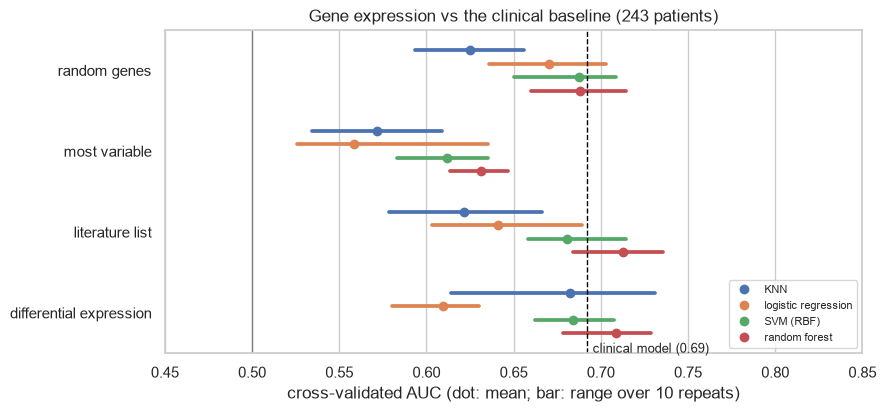

In [5]:
SELECTORS = {
    "random genes": GeneSelector(k=200, method="random", seed=SEED),
    "most variable": GeneSelector(k=200, method="variance"),
    "literature list": GeneSelector(k=200, method="fixed", genes=literature),
    "differential expression": GeneSelector(k=200, method="mannwhitney"),
}
CLASSIFIERS = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "logistic regression": LogisticRegression(max_iter=2000),
    "SVM (RBF)": SVC(probability=True, class_weight="balanced", random_state=SEED),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
}
start = time.perf_counter()
grid = {}
for sname, selector in SELECTORS.items():
    for cname, clf in CLASSIFIERS.items():
        grid[(sname, cname)] = cv_auc(make_pipeline(selector, StandardScaler(), clf), expr)
print(f"16 combinations × {REPEATS} repeats × 5 folds in {time.perf_counter() - start:.0f} s")
grid_table = (
    pd.DataFrame({k: v.mean() for k, v in grid.items()}, index=["AUC"])
    .T["AUC"]
    .unstack()
    .loc[list(SELECTORS), list(CLASSIFIERS)]
)
display(grid_table.round(3))

fig, ax = plt.subplots(figsize=(9, 4.2))
long = pd.DataFrame([{"genes": s, "classifier": c, "AUC": a} for (s, c), v in grid.items() for a in v])
sns.pointplot(data=long, x="AUC", y="genes", hue="classifier", errorbar=("pi", 100), dodge=0.5, linestyles="none",
              markersize=5, ax=ax)  # fmt: skip
clin = results["clinical: ISUP grade + T stage + log PSA"].mean()
ax.axvline(clin, color="black", ls="--", lw=1)
ax.text(clin + 0.003, 3.45, f"clinical model ({clin:.2f})", fontsize=9, va="center")
ax.axvline(0.5, color="grey", lw=1)
ax.set(xlabel="cross-validated AUC (dot: mean; bar: range over 10 repeats)", ylabel="", xlim=(0.45, 0.85),
       title="Gene expression vs the clinical baseline (243 patients)")  # fmt: skip
ax.legend(fontsize=8, loc="lower right")
fig.savefig(FIGURES / "01_expression_vs_clinical.png", dpi=150, bbox_inches="tight")
plt.show()

**No expression model clearly beats the clinical baseline (0.69), and the choice of genes matters less than expected:**

* The best combinations (literature list or differential expression with a random forest, 0.71) are only about
  0.02 above the clinical model; most are below it.
* **200 random genes do about as well as 200 carefully chosen ones** (random forest 0.688; logistic regression 0.670,
  better than with the differentially expressed genes, 0.609). That suggests the recurrence signal is spread across
  many genes rather than concentrated in a few, which fits a broad biological state (such as how fast the tumour
  cells divide) more than a handful of "recurrence genes".
* **The most variable genes are the worst choice** (0.56–0.63): the genes that vary most between tumours
  are not the ones linked to recurrence. They may reflect other differences between samples, such as how much normal
  tissue a sample contains; I did not test which.
* **Logistic regression with 200 differentially expressed genes is the weakest linear model:** with 194 training
  patients and 200 correlated genes, an unregularised linear model overfits. Section 5 tunes this properly.

## 5 · Tuning without cheating: nested cross-validation

Choosing the number of genes and the regularisation strength by looking at cross-validation scores is itself a kind of
fitting. **Nested cross-validation** tunes inside each training fold (an inner 5-fold loop) and evaluates the tuned
model on the untouched outer fold. ([03.2 Lesson on model selection](../../../03_foundations_of_machine_learning/02_hyperparameters_and_performance/LESSONS.md))

Two models, tuned over the number of genes (10, 50, 200) and the strength of regularisation (C = 0.01, 0.1, 1):
expression alone, and **clinical variables plus expression**. 3 repeats of the outer 5-fold loop (each outer fold runs
45 inner fits).

In [6]:
CLIN = ["ISUP grade", "T stage", "log PSA"]
both = pd.concat([clinical[CLIN], expr], axis=1)
genes = list(expr.columns)
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100)
param_grid = {"columntransformer__expression__geneselector__k": [10, 50, 200],
              "logisticregression__C": [0.01, 0.1, 1.0]}  # fmt: skip


def expression_block():
    return make_pipeline(GeneSelector(k=50), StandardScaler())


models = {
    "expression only (tuned)": ColumnTransformer([("expression", expression_block(), genes)]),
    "clinical + expression (tuned)": ColumnTransformer([
        ("clinical", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), CLIN),
        ("expression", expression_block(), genes)]),
}  # fmt: skip
start = time.perf_counter()
oof = {}
for name, features in models.items():
    tuned = GridSearchCV(
        make_pipeline(features, LogisticRegression(max_iter=2000)), param_grid, cv=inner, scoring="roc_auc"
    )
    results[name], oof[name] = cv_auc(tuned, both, repeats=3, return_predictions=True)
results["clinical: ISUP grade + T stage + log PSA (3 repeats)"], oof["clinical"] = cv_auc(
    clinical_model, clinical[CLIN], repeats=3, return_predictions=True)  # fmt: skip
print(f"nested cross-validation took {time.perf_counter() - start:.0f} s")
for name in ("clinical: ISUP grade + T stage + log PSA (3 repeats)", *models):
    print(f"{name:55s} AUC {summary(results[name])}")

nested cross-validation took 550 s
clinical: ISUP grade + T stage + log PSA (3 repeats)    AUC 0.690 (repeats 0.674–0.702)
expression only (tuned)                                 AUC 0.694 (repeats 0.659–0.718)
clinical + expression (tuned)                           AUC 0.713 (repeats 0.683–0.731)


In [7]:
# Are the two models' differences real? Paired bootstrap over patients, on the out-of-fold risk scores
def paired_auc_bootstrap(p_a, p_b, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        diffs.append(roc_auc_score(y[i], p_a[i]) - roc_auc_score(y[i], p_b[i]))
    return np.mean(diffs), *np.percentile(diffs, [2.5, 97.5])


for a, b in (("clinical + expression (tuned)", "clinical"), ("expression only (tuned)", "clinical")):
    d, lo, hi = paired_auc_bootstrap(oof[a], oof[b])
    print(f"{a} − {b}: AUC difference {d:+.3f} (95 % interval {lo:+.3f} to {hi:+.3f})")

rho = spearmanr(oof["expression only (tuned)"], clinical["ISUP grade"]).statistic
print(f"\nSpearman correlation between the expression model's risk score and ISUP grade: {rho:.2f}")

clinical + expression (tuned) − clinical: AUC difference +0.034 (95 % interval -0.044 to +0.111)


expression only (tuned) − clinical: AUC difference +0.016 (95 % interval -0.064 to +0.099)

Spearman correlation between the expression model's risk score and ISUP grade: 0.52


**Tuned honestly, expression reaches the clinical model's level, and adding it to the clinical variables helps at
most a little:**

| Model (3 repeats of nested 5-fold cross-validation) | AUC |
|---|---|
| clinical (ISUP grade + T stage + PSA) | 0.690 |
| expression only (tuned) | 0.694 |
| clinical + expression (tuned) | 0.713 |

* The gain from adding expression to the clinical variables is **+0.034, with a 95 % interval from −0.044 to
  +0.111**. With 243 patients, the data can't tell a useful improvement from no improvement at all.
* **Expression largely re-measures the grade:** the expression model's risk score correlates with ISUP grade
  (Spearman 0.52). Genes can "predict" recurrence partly because they reflect how aggressive the tumour looks, which
  the pathologist already reports.

> **In plain language.** "Our gene signature predicts recurrence with AUC 0.69" sounds like a discovery; "…and so
> does the grade on the pathology report" is the context that decides whether it is useful. Always compare to what
> is already known.

## 6 · The single-split lottery

The course evaluates each model once, on a 30 % test set (73 patients, about 22 recurrences). How much would that
number change with a different random split? 200 random 70/30 splits, two fixed models:

took 42 s


,count,mean,std,min,2.5%,50%,97.5%,max
model,,,,,,,,
200 DE genes + logistic regression,200.0,0.624,0.052,0.468,0.519,0.623,0.720,0.761
clinical (ISUP + T + PSA),200.0,0.700,0.052,0.554,0.607,0.697,0.804,0.848


the clinical model scores higher on 86% of the 200 splits


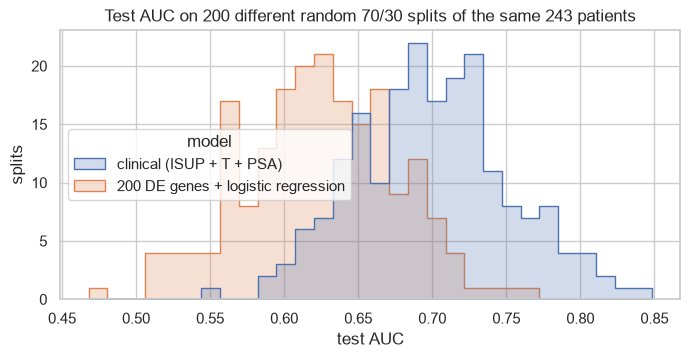

In [8]:
lottery_models = {
    "clinical (ISUP + T + PSA)": (clinical_model, clinical[CLIN]),
    "200 DE genes + logistic regression": (
        make_pipeline(GeneSelector(k=200), StandardScaler(), LogisticRegression(max_iter=2000)),
        expr,
    ),
}
rows = []
start = time.perf_counter()
for seed in range(200):
    train, test = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=seed)
    for name, (model, X) in lottery_models.items():
        m = clone(model).fit(X.iloc[train], y[train])
        rows.append(
            {
                "model": name,
                "split": seed,
                "test AUC": roc_auc_score(y[test], m.predict_proba(X.iloc[test])[:, 1]),
            }
        )
lottery = pd.DataFrame(rows)
print(f"took {time.perf_counter() - start:.0f} s")
display(lottery.groupby("model")["test AUC"].describe(percentiles=[0.025, 0.975]).round(3))
wide = lottery.pivot(index="split", columns="model", values="test AUC")
clin_wins = (wide["clinical (ISUP + T + PSA)"] > wide["200 DE genes + logistic regression"]).mean()
print(f"the clinical model scores higher on {clin_wins:.0%} of the 200 splits")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=lottery, x="test AUC", hue="model", bins=30, element="step", ax=ax)
ax.set(title="Test AUC on 200 different random 70/30 splits of the same 243 patients", ylabel="splits")
fig.savefig(FIGURES / "02_split_lottery.png", dpi=150, bbox_inches="tight")
plt.show()

**A single 73-patient test set is a lottery.** The same model's test AUC ranges from about **0.52 to 0.72** (middle
95 % of 200 splits) depending only on which patients land in the test set; the clinical model ranges from 0.61 to
0.80. The course's one-split differences between classifiers (0.54 to 0.72) fit inside that spread, so they can't
rank the models.

The **clinical model scores higher on 86 % of the splits.** Seen one split at a time, the expression model would
still "win" one time in seven.

> **In plain language.** With few patients, report results over many splits (or with a confidence interval), and
> compare models on the *same* splits. One test-set number is an anecdote.

## 7 · Which genes? Stability of the selection

A gene list is only worth interpreting if it comes back when the data change a little. How often is each gene among
the 200 most differentially expressed when selection is repeated on each of 50 training folds?

In [9]:
counts = pd.Series(0, index=expr.columns)
for r in range(REPEATS):
    for train, _ in StratifiedKFold(n_splits=5, shuffle=True, random_state=r).split(expr, y):
        counts[GeneSelector(k=200).fit(expr.iloc[train], y[train]).genes_] += 1
freq = counts / (5 * REPEATS)
print(f"genes selected at least once: {(freq > 0).sum():,}; in every one of the 50 folds: {(freq == 1).sum()}; "
      f"in ≥ 80 % of folds: {(freq >= 0.8).sum()}")  # fmt: skip

stable = freq[freq >= 0.8].index
direction = np.sign(expr.loc[y == 1, stable].mean() - expr.loc[y == 0, stable].mean())
grade_rho = expr[stable].apply(lambda g: spearmanr(g, clinical["ISUP grade"]).statistic)
top = pd.DataFrame({"selected in % of folds": (100 * freq[stable]).round(0),
                    "higher in": direction.map({1.0: "recurrence", -1.0: "no recurrence"}),
                    "correlation with ISUP grade": grade_rho.round(2),
                    "in literature list": [g in set(literature) for g in stable]}).sort_values(
    ["selected in % of folds", "correlation with ISUP grade"], ascending=False)  # fmt: skip
print(f"stable genes higher in recurrence: {(direction > 0).mean():.0%}; median |correlation with grade|: "
      f"{grade_rho.abs().median():.2f}; in the literature list: {top['in literature list'].sum()}")  # fmt: skip
top.to_csv(RESULTS / "stable_genes.csv")
top.head(15)

genes selected at least once: 869; in every one of the 50 folds: 15; in ≥ 80 % of folds: 73
stable genes higher in recurrence: 95%; median |correlation with grade|: 0.34; in the literature list: 3


,selected in % of folds,higher in,correlation with ISUP grade,in literature list
EME1,100.0,recurrence,0.44,False
PARP2,100.0,recurrence,0.43,True
ARHGAP33,100.0,recurrence,0.41,False
C1orf104,100.0,recurrence,0.41,False
FUS,100.0,recurrence,0.39,False
WDR5,100.0,recurrence,0.39,False
HNRNPH1,100.0,recurrence,0.38,False
DSN1,100.0,recurrence,0.38,False
COL11A2,100.0,recurrence,0.34,False
ANKRD13D,100.0,recurrence,0.33,False


**Few genes are reliably selected, and they mostly track grade.** Across the 50 training folds, 869 different genes
entered the top 200 at least once, but only **73 were selected in at least 80 % of folds** (15 in every fold). Of
those 73:

* **95 % are more active in tumours that recurred**, and they correlate with ISUP grade (median |ρ| = 0.34);
* only **3 are on the course's 490-gene literature list** (e.g. *PARP2*, a DNA-repair gene).

Several of the most stable genes have roles in DNA repair and cell division (*EME1*, *PARP2*, *DSN1*), which
is consistent with aggressive, fast-dividing tumours. That is a hypothesis from a handful of names, not a test:
[notebook 02](02_survival_and_pathways.ipynb) runs a proper pathway analysis. The full table is saved in
[`results/stable_genes.csv`](results/stable_genes.csv).

## Conclusions

1. **The clinical baseline is strong:** ISUP grade alone gives AUC 0.69, and no expression model clearly beats it.
   Tuned expression models reach 0.69, and clinical + expression 0.71, a gain the data can't distinguish from zero
   (95 % interval −0.04 to +0.11).
2. **Leakage is the biggest effect in the project.** Selecting genes before cross-validation turned pure noise into
   AUC 0.74; only selection inside each training fold scores noise at chance.
3. **Gene choice mattered less than expected:** random genes did about as well as selected ones, and the most
   variable genes did worst. The signal is broad and overlaps with tumour grade.
4. **One test split can't rank models:** test AUC for the same model spans about 0.2 across random splits.

**Limitations.** 243 patients from one source (TCGA), so no external validation. The 3-year outcome discards
follow-up time and excludes patients followed for less than 3 years; [notebook 02](02_survival_and_pathways.ipynb)
uses the full time-to-event data instead. The classifiers use mostly default settings (only the logistic models were
tuned), and the literature list is used in its given order, as in the course.

*Data: TCGA PRAD as prepared by the course (UCSC Xena), downloaded to the git-ignored `data/raw/` by
`scripts/fetch_course_materials.sh --data`. Runtime: about 12 minutes on an Apple-silicon laptop (nested
cross-validation is most of it).*